In [2]:
import os
import random
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ["PYTHONHASHSEED"] = str(SEMILLA)

RUTA = "../../s23-feature-engineering-clinico/tu-entrega/features.csv"
df = pd.read_csv(RUTA, parse_dates=["fecha_indice"])
df = df.sort_values("fecha_indice").reset_index(drop=True)

corte = df["fecha_indice"].quantile(0.8)
entreno = df[df["fecha_indice"] < corte]
prueba = df[df["fecha_indice"] >= corte]

NO_FEATURES = ["person_id", "fecha_indice", "muerte_90d"]
X_train = entreno.drop(columns=NO_FEATURES)
y_train = entreno["muerte_90d"]
X_test = prueba.drop(columns=NO_FEATURES)
y_test = prueba["muerte_90d"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print("Corte temporal:", corte.date())
print(f"Entrenamiento: {X_train.shape}, muertes {y_train.sum()} ({y_train.mean():.2%})")
print(f"Prueba:        {X_test.shape}, muertes {y_test.sum()} ({y_test.mean():.2%})")

Corte temporal: 2023-01-27
Entrenamiento: (4296, 34), muertes 306 (7.12%)
Prueba:        (1076, 34), muertes 63 (5.86%)


In [3]:
np.random.seed(42)
print(np.random.rand(3))
np.random.seed(42)
print(np.random.rand(3))

[0.37454012 0.95071431 0.73199394]
[0.37454012 0.95071431 0.73199394]


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def con_escala(modelo):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         StandardScaler(),
                         modelo)

def sin_escala(modelo):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                         modelo)

catalogo = {
    "DummyClassifier": sin_escala(DummyClassifier(strategy="prior")),
    "Regresión logística": con_escala(LogisticRegression(C=1.0, max_iter=2000)),
    "k-NN": con_escala(KNeighborsClassifier(n_neighbors=25)),
    "SVM (RBF)": con_escala(SVC(kernel="rbf", random_state=SEMILLA)),
    "Random Forest": sin_escala(RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEMILLA)),
    "XGBoost": sin_escala(XGBClassifier(n_estimators=300, n_jobs=-1, random_state=SEMILLA)),
    "LightGBM": sin_escala(LGBMClassifier(n_estimators=300, random_state=SEMILLA, verbose=-1)),
}

filas = []
for nombre, pipe in catalogo.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring=["roc_auc", "average_precision"])
    filas.append({
        "modelo": nombre,
        "AUROC": res["test_roc_auc"].mean(),
        "AUROC_de": res["test_roc_auc"].std(),
        "AUPRC": res["test_average_precision"].mean(),
        "AUPRC_de": res["test_average_precision"].std(),
        "tiempo_s": res["fit_time"].sum(),
    })
    print(f"{nombre:20s} listo")

catalogo_res = pd.DataFrame(filas).sort_values("AUROC", ascending=False)
catalogo_res.round(3)

DummyClassifier      listo
Regresión logística  listo
k-NN                 listo
SVM (RBF)            listo
Random Forest        listo
XGBoost              listo
LightGBM             listo


,modelo,AUROC,AUROC_de,AUPRC,AUPRC_de,tiempo_s
4,Random Forest,0.832,0.022,0.425,0.029,4.083
6,LightGBM,0.811,0.018,0.380,0.027,1.106
5,XGBoost,0.802,0.012,0.368,0.028,4.606
1,Regresión logística,0.791,0.019,0.231,0.017,0.093
2,k-NN,0.776,0.022,0.244,0.022,0.083
3,SVM (RBF),0.723,0.020,0.293,0.023,0.538
0,DummyClassifier,0.500,0.000,0.071,0.000,0.047


## Actividad 2. 

**Random Forest (1.º, AUROC 0.832, AUPRC 0.425).** Supone que el riesgo se arma con umbrales e interacciones , sin pedir que la relación sea lineal. Además promedia 500 árboles hechos con submuestras distintas, y eso reduce la varianza. Con solo 306 eventos, ese promedio lo hace robusto, y por eso ganó sin ajustar nada.

**LightGBM (2.º, 0.811) y XGBoost (3.º, 0.802).** También capturan umbrales e interacciones, pero construyen los árboles en secuencia, cada uno corrigiendo los errores del anterior. Con los valores por defecto (300 árboles, sin early stopping, `num_leaves=31` en LightGBM) son demasiado flexibles para unos miles de filas y tienden a sobreajustar. Por eso quedan detrás del bosque. Se espera que suban al ajustarlos (actividades 3 a 6).

**Regresión logística (4.º, 0.791 pero AUPRC 0.231).** Supone que cada variable suma riesgo de forma lineal y monótona en la escala logit. El AUROC queda cerca porque muchas de mis variables ya son riesgos monótonos (edad, insuficiencia cardiaca, albúmina baja). El AUPRC tan bajo indica que no logra concentrar las muertes en el extremo de mayor riesgo: le faltan las interacciones y los umbrales que sí ven los árboles.

**SVM con kernel RBF (el peor, después del Dummy; 0.723).** Supone que pacientes cercanos en distancia euclidiana, con todas las variables escaladas, tienen el mismo desenlace. Con 34 variables más los indicadores, muchas binarias o poco informativas, todas pesan igual en la distancia y el ruido tapa la señal. Además, con 7 % de eventos el margen lo dominan los sobrevivientes. Fue rápido (0.5 s), pero no aportó nada sobre modelos más simples. k-NN (0.776) sufre por el mismo supuesto de distancia.

In [5]:
resultados_nl = []
for hojas, profundidad in [(31, -1), (7, 3)]:
    pipe = sin_escala(LGBMClassifier(n_estimators=300, num_leaves=hojas, max_depth=profundidad,
                                     random_state=SEMILLA, verbose=-1))
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring=["roc_auc", "average_precision"],
                         return_train_score=True)
    resultados_nl.append({
        "num_leaves": hojas,
        "max_depth": profundidad,
        "AUROC_entreno": res["train_roc_auc"].mean(),
        "AUROC_cv": res["test_roc_auc"].mean(),
        "AUROC_de": res["test_roc_auc"].std(),
        "AUPRC_cv": res["test_average_precision"].mean(),
        "AUPRC_de": res["test_average_precision"].std(),
    })
pd.DataFrame(resultados_nl).round(3)

,num_leaves,max_depth,AUROC_entreno,AUROC_cv,AUROC_de,AUPRC_cv,AUPRC_de
0,31,-1,1.000,0.811,0.018,0.380,0.027
1,7,3,0.992,0.807,0.011,0.356,0.036


## Actividad 3. LightGBM y num_leaves

| num_leaves | max_depth | AUROC entreno | AUROC CV (DE) | AUPRC CV (DE) |
|---|---|---|---|---|
| 31 (defecto) | sin límite | 1.000 | 0.811 (0.018) | 0.380 (0.027) |
| 7 | 3 | 0.992 | 0.807 (0.011) | 0.356 (0.036) |

Con el valor por defecto el modelo memoriza el entrenamiento (AUROC 1.000) y cae a 0.811 en validación, que es sobreajuste. Reducir a 7 hojas, con max_depth=3, casi no cerró la brecha (0.992 contra 0.807). En esta cohorte, el sobreajuste viene al parecer de acumular 300 árboles sin control: el número de árboles es lo que hay que frenar.

/home/alecedillo/s10-sql-fundamentals/venv/lib64/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Ajuste: 3436 | Validación: 860 | Prueba (sin tocar): 1076
Se detuvo en 124 árboles; AUROC de validación = 0.836


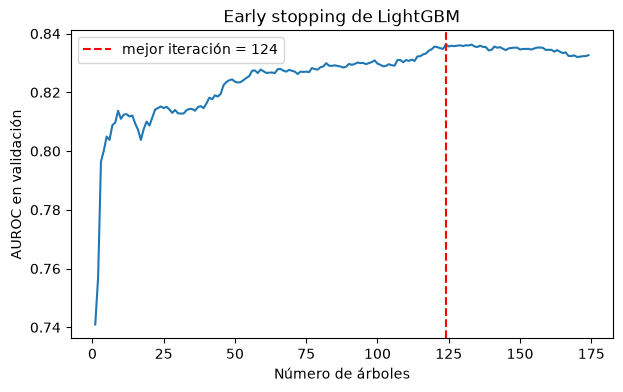

In [6]:
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

X_ajuste, X_val, y_ajuste, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEMILLA)

imputador = SimpleImputer(strategy="median", add_indicator=True)
X_ajuste_imp = imputador.fit_transform(X_ajuste)
X_val_imp = imputador.transform(X_val)

historia = {}
modelo_es = LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=7, max_depth=3,
                           random_state=SEMILLA, verbose=-1)
modelo_es.fit(X_ajuste_imp, y_ajuste,
              eval_set=[(X_val_imp, y_val)],
              eval_metric="auc",
              callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False),
                         lgb.record_evaluation(historia)])

mejor = modelo_es.best_iteration_
auc_val = roc_auc_score(y_val, modelo_es.predict_proba(X_val_imp)[:, 1])
print(f"Ajuste: {X_ajuste.shape[0]} | Validación: {X_val.shape[0]} | Prueba (sin tocar): {X_test.shape[0]}")
print(f"Se detuvo en {mejor} árboles; AUROC de validación = {auc_val:.3f}")

curva = historia["valid_0"]["auc"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(curva) + 1), curva)
ax.axvline(mejor, color="red", linestyle="--", label=f"mejor iteración = {mejor}")
ax.set_xlabel("Número de árboles")
ax.set_ylabel("AUROC en validación")
ax.set_title("Early stopping de LightGBM")
ax.legend()
fig.savefig("curva_early_stopping.png", dpi=150, bbox_inches="tight")
plt.show()

## Actividad 4. Early stopping con tres conjuntos

Tres conjuntos: ajuste (3,436), validación (860) y prueba (1,076). LightGBM con learning_rate=0.05, num_leaves=7, max_depth=3, techo de 2000 árboles y paciencia de 50.

- Se detuvo en **124 árboles**, con AUROC de validación de **0.836**.
- Curva: `curva_early_stopping.png`. Sube rápido hasta unos 25 árboles, llega a una meseta hacia los 60 y deja de mejorar después de 124, así que los 300 árboles por defecto de la actividad 3 eran más de lo necesario.

El early stopping elige un hiperparámetro (el número de árboles) mirando la métrica del conjunto que recibe. 